# Genetic Risk Prediction: Data Wrangling (NBK 1)

This notebook focuses on loading, quality-checking, and aligning the primary inputs: 1000 Genomes EUR genotypes, Geuvadis gene expression, and the gene annotation. This is to establish the shared cohort and protein-coding gene set used by every downstream notebook.

To begin, the following prerequisites are required to run this notebook without any errors:

- `data/genotype/LDREF/` populated with the 1000G EUR PLINK filesets (`1000G.EUR.{1..22}.{bed,bim,fam}`)
- `data/phenotype/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt.gz` (Geuvadis expression matrix)
- `data/annotation/gene_annot.txt.gz` (gene annotation table)
- Python environment with `numpy`, `pandas`, `matplotlib`, `bed-reader` installed (see `requirements.txt`)
- `helpers.py` present in the same directory as this notebook

---

### Import statements

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import helpers

---

### Understanding the gene expression data (Geuvadis LCLs)

The gene expression data comes from the **Geuvadis** consortium, which RNA-sequenced **lymphoblastoid cell lines (LCLs)** from **462 individuals who are also in the 1000 Genomes Project**. This overlap is useful as it will let us link each person's *expression* to their *genotype* for cis-eQTL mapping.

Each value is a gene's **RPKM (Reads Per Kilobase Million)**. This is a length- and depth-normalized expression level, where higher values indicate more expression.

In [10]:
expression_df = helpers.read_expression()
expression_df.head()

,TargetID,Gene_Symbol,Chr,Coord,HG00096,HG00097,HG00099,HG00100,HG00101,HG00102,...,NA20810,NA20811,NA20812,NA20813,NA20814,NA20815,NA20816,NA20819,NA20826,NA20828
0,ENSG00000152931.6,ENSG00000152931.6,5,59783540,0.101858,0.078110,0.048981,0.118597,0.004035,0.010925,...,0.088601,0.240010,0.137175,0.148494,0.038643,0.088509,0.029204,0.024423,0.044816,0.139186
1,ENSG00000183696.9,ENSG00000183696.9,7,48128225,8.183805,5.686911,2.434653,3.830894,6.612288,4.709646,...,13.428205,6.094500,12.536000,2.217262,3.573394,7.583364,4.052882,1.570378,4.900372,6.737308
2,ENSG00000139269.2,ENSG00000139269.2,12,57846106,1.199910,1.573572,0.521616,1.447225,3.565791,1.982681,...,3.225880,1.996067,2.854923,2.267343,1.331201,2.187895,1.004250,3.003316,1.984362,1.684954
3,ENSG00000169129.8,ENSG00000169129.8,10,116164515,0.831940,0.069778,0.931086,0.620941,1.660668,0.570481,...,1.023381,1.127852,0.774409,1.495854,0.895342,1.513521,0.826377,1.021201,0.952502,0.740565
4,ENSG00000134602.11,ENSG00000134602.11,X,131157293,27.646422,24.395572,16.445374,24.806650,25.113349,19.233988,...,25.079490,28.725528,24.450520,27.264069,26.912814,29.509210,26.462331,25.624009,25.707741,22.824957


This loads the matrix (`expression_df`, 23,722 genes × 462 samples), with 4 metadata columns and corresponding RPKM values per sample.

In [16]:
metadata_columns = ["TargetID", "Gene_Symbol", "Chr", "Coord"]
sample_ids = []
for column in expression_df:
    if column not in metadata_columns:
        sample_ids.append(column)
print(f"There are {len(sample_ids)} samples.")
sample_ids[:5]

There are 462 samples.


['HG00096', 'HG00097', 'HG00099', 'HG00100', 'HG00101']

This extracts the list of 462 sample IDs (`sample_ids`) and prints the first 5 IDs.

---

### Understanding the genotype data (1000 Genomes EUR reference)

The genotype data comes from the **1000 Genomes Project**, the standard reference catalog of human genetic variation. Specifically, we use the **FUSION LDREF panel**, which is a curated subset of **489 individuals of European ancestry** and about **1.19 million common SNPs**, distributed as per-chromosome **PLINK filesets**.

Each chromosome is split across three sibling files sharing a prefix:
- **`.bed`** — compact binary matrix of genotype dosages (0 / 1 / 2 copies of the alternative allele per person × SNP)
- **`.bim`** — SNP metadata (chromosome, rsID, cM distance, position, two alleles)
- **`.fam`** — sample metadata (family and individual IDs, sex, phenotype)

Chromosome 22 is used below as a probe to confirm the data loads cleanly. The full genome works identically.


In [24]:
genotype_matrix = helpers.read_genotypes(helpers.ldref_prefix(22))[0]
iids = helpers.read_genotypes(helpers.ldref_prefix(22))[1]
bim_df = helpers.read_genotypes(helpers.ldref_prefix(22))[2]
print(f"Genotype samples: {len(iids)}")
print(f"Chromosome 22 SNPs: {genotype_matrix.shape[1]}")
bim_df.head()

Genotype samples: 489
Chromosome 22 SNPs: 17489


,chr,snp,cm,pos,a1,a2
0,22,rs9617528,0.059576,16061016,C,T
1,22,rs4911642,2.127458,16504399,C,T
2,22,rs7287144,2.252105,16886873,G,A
3,22,rs5748662,2.255191,16892858,A,G
4,22,rs5994034,2.255836,16894090,T,C


This loads chromosome 22 of the EUR reference panel: a 489 × 17,489 dosage matrix (`genotype_matrix`), a list of 489 individual IDs (`iids`), and the SNP table (`bim_df`). Each `.bim` row describes one SNP: chromosome, rsID, genetic distance in cM, base-pair position, and the two alleles observed.

---

### Understanding allele frequencies (MAF)

Every SNP has 2 alleles; the **minor allele frequency (MAF)** is the frequency of whichever is rarer in the population, bounded between 0 and 0.5. MAF matters because:
- **Rare variants (MAF < 0.01)** are hard to study statistically as fewer carriers means less power to detect associations. These are typically dropped because their effects cannot be reliably estimated.
- **Common variants (MAF ≥ 0.05)** are the backbone of GWAS as most published associations sit at common SNPs.

We can estimate each SNP's MAF from the mean dosage: if genotypes are coded 0/1/2 (count of the alternative allele), then mean dosage ÷ 2 is the alternative-allele frequency, and `MAF = min(alt_freq, 1 − alt_freq)`.


In [36]:
alt_freq = np.nanmean(genotype_matrix, axis=0) / 2.0
maf = np.minimum(alt_freq, 1.0 - alt_freq)
maf_class = pd.cut(maf, bins=[0, 0.01, 0.05, 0.5], labels=["Rare variants", "Low frequency variants", "Common variants"], include_lowest=True)
counts = pd.Series(maf_class).value_counts().rename("count")
maf_df = pd.DataFrame({"count": counts, "proportion": counts / counts.sum()})
maf_df

,count,proportion
Common variants,15633,0.893876
Low frequency variants,1645,0.094059
Rare variants,211,0.012065


On chromosome 22 of the EUR panel, ~89% of SNPs are common (MAF ≥ 0.05), 9.4% are low-frequency, and 1.2% are rare.

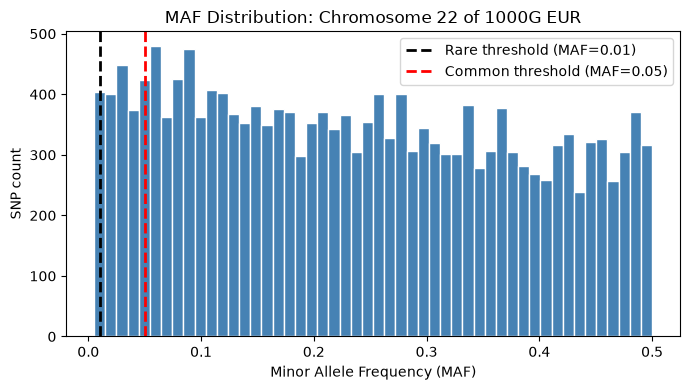

In [48]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(maf, bins=50, color='steelblue', edgecolor='white')
ax.set(xlabel='Minor Allele Frequency (MAF)', ylabel='SNP count',
       title='MAF Distribution: Chromosome 22 of 1000G EUR')
ax.axvline(0.01, color='black', ls='--', lw=2, label='Rare threshold (MAF=0.01)')
ax.axvline(0.05, color='red',   ls='--', lw=2, label='Common threshold (MAF=0.05)')
ax.legend()
fig.tight_layout()
plt.show()

This histogram confirms that the mass of SNPs sits at moderate-to-high MAF, with very few near 0. This is consistent with the panel's design.

---

### Understanding the sample overlap

cis-eQTL regression correlates each SNP's **genotype** with a gene's **expression** in the same individual, which means we need people who have **both** measurements. The two datasets don't perfectly line up:

- The **1000 Genomes EUR LDREF panel** contains **489** European individuals (genotypes only)
- The **Geuvadis** expression dataset contains **462** individuals drawn from 1000 Genomes across 5 populations: 4 European + Yoruban, none of whom have EUR-only LDREF genotypes

As such, the usable cohort is the **intersection**: Europeans who have both LDREF genotypes and Geuvadis expression.

We can check overlap using Chromosome 22's `iids`, but the same 489 individuals appear in every chromosome's `.fam` file. Therefore, the overlap count below is genome-wide and not specific to Chromosome 22.


In [50]:
shared_individuals = sorted(set(str(i) for i in iids) & set(sample_ids))
print(f"Genotype individuals: {len(iids)}")
print(f"Expression individuals: {len(sample_ids)}")
print(f"Shared individuals (intersection): {len(shared_individuals)}")

Genotype individuals: 489
Expression individuals: 462
Shared individuals (intersection): 344


344 individuals have both genotype and expression. Of the 489 individuals genotyped, 145 lack expression data (as they are not in Geuvadis). Similarly, of the 462 with expression data, 118 lack EUR LDREF genotypes (mostly consisting of Yoruban individuals).


---

### Understanding the protein-coding gene set

Not every gene makes a protein. The annotation table lists 20,500 genes, but they fall into many biological categories, namely: 
- **protein-coding** genes, plus various non-coding types such as
- **miRNAs** (small regulators),
- **lincRNAs** (long non-coding),
- **pseudogenes** (broken gene copies), etc.

This analysis specifically focuses on **protein-coding genes**. Subsetting to protein-coding keeps ~17,000 genes out of the ~20,000. Each retained gene's `START` and `STOP` coordinates define the ±500 kb cis-window used downstream.

In [62]:
annotation_df = helpers.read_gene_annotation()
protein_coding = annotation_df[annotation_df["TYPE"] == "protein_coding"]
print(f"Total genes across the genome: {len(annotation_df)}")
print(f"Protein-coding genes across the genome: {len(protein_coding)}")
print(f"Protein-coding genes on Chromosome 22: {(protein_coding['CHR'] == 22).sum()}")
protein_coding[protein_coding['CHR'] == 22].head()

Total genes across the genome: 20500
Protein-coding genes across the genome: 17231
Protein-coding genes on Chromosome 22: 396


,ID,CHR,START,STOP,SYM,TYPE
20010,OR11H1,22,15528157,15529139,ENSG00000130538,protein_coding
20011,POTEH,22,15690025,15721522,ENSG00000198062,protein_coding
20012,CCT8L2,22,16590776,16592810,ENSG00000198445,protein_coding
20015,XKR3,22,16783411,16821699,ENSG00000172967,protein_coding
20017,GAB4,22,16961935,17008222,ENSG00000215568,protein_coding


Of the 20,500 total genes, 17,231 are protein-coding with 396 on Chromosome 22. Each row gives the gene's chromosome, start/stop coordinates, Ensembl ID (a database identifier in genomics), and gene symbol. This is useful to look up a gene and define its cis-window.

---